<div dir="rtl" style="text-align: right;">

# چالش آماری علم داده ترم 3 (شماره 3)

- نام: Kiarash Akbari
- مجموعه: آزمایشگاه فناوری های مالی داتین
- تاریخ: 5 آبان 1405
- فایل داده: bank_season3_part2.csv با 600 مشتری بانک
- پاسخ: log_avg_balance برای هر دو سوال

### 1. تنظیمات اولیه

seed را 42 می گذارم. برازش و انتخاب مدل فقط روی train است و test فقط برای گزارش خطا. چیزی را با نگاه به خطای test تنظیم نمی کنم. نمودارها و خروجی ها داخل همین فایل ذخیره می شوند.

</div>

In [1]:
import io
import warnings
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LassoCV, enet_path, lars_path
from sklearn.model_selection import KFold, cross_val_score
from IPython.display import display, Image

SEED = 42
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
plt.rcParams['figure.dpi'] = 110

def show():
    b = io.BytesIO()
    plt.gcf().savefig(b, format='png', bbox_inches='tight')
    plt.close()
    display(Image(b.getvalue()))

def find_data():
    p = Path.cwd().resolve()
    for f in [p, *p.parents]:
        for q in [f / 'bank_season3_part2.csv', f / 'dataset' / 'bank_season3_part2.csv',
                  f / 'datasets' / 'bank_season3_part2.csv', f / 'term-3' / 'datasets' / 'bank_season3_part2.csv']:
            if q.exists():
                return q
    raise FileNotFoundError('bank_season3_part2.csv not found')

DATA_PATH = find_data()
raw = pd.read_csv(DATA_PATH)
print('shape:', raw.shape)
print('split:', raw['split'].value_counts().to_dict())
print('missing:', raw.isna().sum().loc[lambda s: s > 0].to_dict())
print('duplicate rows:', raw.duplicated().sum(), '| unique id:', raw['customer_id'].is_unique)
print('missing avg_overdraft iff no event:',
      ((raw['n_overdraft'] == 0) == raw['avg_overdraft_mrial'].isna()).all())
assert raw['split'].value_counts().to_dict() == {'test': 450, 'train': 150}
assert raw['customer_id'].is_unique

shape: (600, 35)
split: {'test': 450, 'train': 150}
missing: {'avg_overdraft_mrial': 212}
duplicate rows: 0 | unique id: True
missing avg_overdraft iff no event: True


<div dir="rtl" style="text-align: right;">

600 سطر و 35 ستون داریم، train برابر 150 و test برابر 450. شناسه تکراری نداریم. فقط avg_overdraft_mrial خالی دارد، 212 سطر و دقیقا همان مشتری هایی که اضافه برداشت ندارند. این گمشدگی ساختاری است و چیزی را پر نمی کنم.

### 2. آماده کردن 30 پیش بین

customer_id و split و پاسخ پیش بین نیستند. exposure_months و n_overdraft و avg_overdraft_mrial را هم کنار می گذارم، چون بدون آن ها و با دو دامی شعبه دقیقا 30 پیش بین صورت سوال ساخته می شود. این برداشت من از شمارش سوال است. چهار متغیر درآمدی و چهار متغیر هزینه کارتی را جدا لیست می کنم که بعدا جابه جا نشوند.

Metro را مرجع می گذارم. هیچ سطری حذف نمی شود. میانگین و انحراف معیار نمونه ای فقط از train می آیند، حتی برای دامی ها. score ها هم دوباره با train استاندارد می شوند، چون استاندارد بودن روی کل داده کافی نیست.

</div>

In [2]:
income4 = ['salary_inflow_rial', 'total_inflow_mrial', 'avg_monthly_credit_mrial', 'declared_income_mrial']
card4 = ['card_spend_total_mrial', 'card_spend_online_mrial', 'card_spend_pos_mrial', 'n_card_tx']
scores = [f'score_{i:02d}' for i in range(1, 11)]
basic = ['age', 'tenure_years', 'n_products', 'Town', 'Rural']
extra = ['savings_ratio', 'credit_utilization', 'mobile_logins', 'loan_balance_mrial',
         'branch_visits', 'atm_withdrawals', 'credit_limit_mrial']
cols = basic + income4 + card4 + extra + scores

df = raw.copy()
assert set(df['branch_type']) == {'Metro', 'Town', 'Rural'}
df['Town'] = (df['branch_type'] == 'Town').astype(float)
df['Rural'] = (df['branch_type'] == 'Rural').astype(float)
train = df.loc[df['split'] == 'train'].copy()
test = df.loc[df['split'] == 'test'].copy()
mu = train[cols].mean()
sd = train[cols].std(ddof=1)
assert len(cols) == len(set(cols)) == 30
assert train[cols].notna().all().all() and test[cols].notna().all().all()
assert (sd > 0).all()
X = ((train[cols] - mu) / sd).to_numpy()
Xt = ((test[cols] - mu) / sd).to_numpy()
y = train['log_avg_balance'].to_numpy()
yt = test['log_avg_balance'].to_numpy()
n, p = X.shape
assert np.allclose(X.mean(0), 0)
assert np.allclose(X.std(0, ddof=1), 1)
print('X train:', X.shape, '| X test:', Xt.shape)
print('rank X:', np.linalg.matrix_rank(X))
print('train mean and SD, income:')
print(pd.DataFrame({'mean': mu[income4], 'sd': sd[income4]}).round(3).to_string())

X train: (150, 30) | X test: (450, 30)
rank X: 30
train mean and SD, income:
                                  mean            sd
salary_inflow_rial        1.644465e+08  7.401025e+07
total_inflow_mrial        2.229360e+02  9.945000e+01
avg_monthly_credit_mrial  1.951850e+02  8.658300e+01
declared_income_mrial     1.813180e+02  8.250700e+01


<div dir="rtl" style="text-align: right;">

### 3. سوال 1-الف: استانداردسازی و OLS

salary_inflow_rial به ریال است و سه متغیر درآمدی دیگر به میلیون ریال. پس یک رابطه مشابه با ضریب خیلی کوچک تری روی حقوق نمایش داده می شود. جریمه روی خود ضریب است، برای همین بدون استانداردسازی حقوق به خاطر واحدش جریمه کمتری می گیرد، نه به خاطر اهمیتش. با استانداردسازی ضرایب همگی برای یک انحراف معیار تغییرند و قابل مقایسه می شوند.

VIF را با معکوس ماتریس همبستگی حساب می کنم و با تابع کتابخانه چک می کنم. نسبت مقدارهای ویژه را برای X استانداردشده بدون عرض از مبدا می خواهم. این نسبت با عدد شرط X یکی نیست و مربع آن است.

</div>

In [3]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
R = np.corrcoef(X, rowvar=False)
vif = pd.Series(np.diag(np.linalg.inv(R)), index=cols)
check = np.array([variance_inflation_factor(sm.add_constant(X), j + 1) for j in range(p)])
assert np.allclose(vif, check)
print('six largest VIF:')
print(vif.sort_values(ascending=False).head(6).round(3).to_string())
eig = np.linalg.eigvalsh(X.T @ X)
print('min and max eigenvalue:', eig[0], eig[-1])
print('eigenvalue ratio:', eig[-1] / eig[0], '| condition X:', np.sqrt(eig[-1] / eig[0]))
ols = sm.OLS(y, sm.add_constant(X)).fit()
ols_test = np.mean((yt - ols.predict(sm.add_constant(Xt, has_constant='add'))) ** 2)
print('OLS train MSE:', ols.ssr / n, '| test MSE:', ols_test, '| sigma2:', ols.mse_resid)
ols_b = pd.Series(ols.params[1:], index=cols)
ols_se = pd.Series(ols.bse[1:], index=cols)
print(pd.DataFrame({'coef per SD': ols_b[income4], 'SE': ols_se[income4],
                    'raw unit coef': ols_b[income4] / sd[income4]}).to_string())

six largest VIF:
card_spend_total_mrial      54.606
salary_inflow_rial          53.933
total_inflow_mrial          41.586
avg_monthly_credit_mrial    30.118
card_spend_pos_mrial        25.654
declared_income_mrial       22.754
min and max eigenvalue: 1.7722073065724029 886.6465425822537
eigenvalue ratio: 500.30633509637323 | condition X: 22.367528587136604
OLS train MSE: 0.8873587258949894 | test MSE: 1.381691438356705 | sigma2: 1.1185194023886422
                          coef per SD        SE  raw unit coef
salary_inflow_rial          -0.150060  0.636293  -2.027555e-09
total_inflow_mrial           0.851930  0.558727   8.566391e-03
avg_monthly_credit_mrial     0.376144  0.475490   4.344296e-03
declared_income_mrial       -0.409573  0.413297  -4.964123e-03


<div dir="rtl" style="text-align: right;">

بیشترین VIF مال card_spend_total_mrial با 54.6 و salary_inflow_rial با 53.9 است. بعد total_inflow_mrial با 41.6، avg_monthly_credit_mrial با 30.1، card_spend_pos_mrial با 25.7 و declared_income_mrial با 22.8. مشکل توی دو گروه درآمد و هزینه کارتی است.

نسبت مقدارهای ویژه حدود 500 است و عدد شرط X حدود 22.4. کوچک ترین مقدار ویژه 1.77 است و رتبه کامل است، پس همخطی کامل نداریم ولی ضرایب گروه ها ناپایدارند.

MSE آموزش 0.8874 و آزمون 1.3817 است. این فاصله با بیش برازش می خورد ولی به تنهایی اثباتش نیست، چون دو نمونه فرق دارند. MSE را با تقسیم RSS بر تعداد مشاهده حساب کردم، نه درجه آزادی باقی مانده.

ضریب درآمدها به ترتیب منفی 0.150 و 0.852 و 0.376 و منفی 0.410 است و SE ها بزرگ اند. این منفی ها را نباید اثر معکوس واقعی دانست، چون متغیرها خیلی هم خط اند و سهم جداگانه شان دقیق برآورد نمی شود. این تفسیر درباره ضرایب استانداردشده است، نه ضریب خام به ازای هر ریال.

### 4. سوال 1-ب: Ridge با CV

همان شبکه صد نقطه ای سوال و CV ده بخشی با shuffle و seed برابر 42 را می گذارم. برای سازگاری با قرارداد صورت سوال X از قبل با کل train استاندارد شده و توی هر فولد فقط میانگین X و y دوباره گرفته می شود. این یعنی مقیاس فولد اعتبارسنجی در محاسبه SD کل train سهم داشته، هرچند test هیچ نقشی ندارد. برای ارزیابی کاملا جدا، مقیاس گذاری هم باید داخل هر فولد باشد که جواب عددی متفاوت می دهد.

خطای معیار را با انحراف معیار نمونه ای خطای فولدها تقسیم بر ریشه تعداد فولد می گیرم، توی lambda_min. بزرگ ترین لامبدای زیر این آستانه همان lambda_1se است. df طبق خود فرمول سوال عرض از مبدا را ندارد. با شمردن عرض از مبدا یک واحد به آن اضافه می شود.

</div>

min | lambda: 30.538555088334157 | CV MSE: 1.3508494111819556 | test MSE: 1.2635558094692485 | df: 20.199269916228268
1se | lambda: 155.56761439304722 | CV MSE: 1.4589962642406877 | test MSE: 1.3570974016427286 | df: 11.737385583676732
SE at min: 0.12299111971513821
                             OLS  Ridge min  Ridge 1se
salary_inflow_rial       -0.1501     0.1662     0.1302
total_inflow_mrial        0.8519     0.1972     0.1298
avg_monthly_credit_mrial  0.3761     0.1704     0.1203
declared_income_mrial    -0.4096     0.0716     0.1058


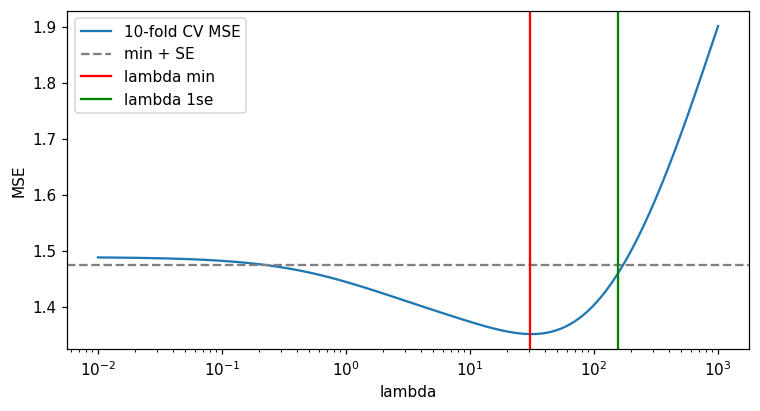

In [4]:
folds = list(KFold(10, shuffle=True, random_state=SEED).split(X))
lambdas = np.logspace(-2, 3, 100)
def ridge_path(A, b, grid):
    am, bm = A.mean(0), b.mean()
    u, s, vt = np.linalg.svd(A - am, full_matrices=False)
    B = np.array([vt.T @ (s / (s*s + lam) * (u.T @ (b-bm))) for lam in grid])
    return B, am, bm

ridge_errors = []
for a, v in folds:
    B, am, bm = ridge_path(X[a], y[a], lambdas)
    pred = (X[v] - am) @ B.T + bm
    ridge_errors.append(np.mean((y[v, None] - pred)**2, axis=0))
ridge_errors = np.array(ridge_errors)
rcv = ridge_errors.mean(0)
rse = ridge_errors.std(0, ddof=1) / np.sqrt(10)
ri = int(rcv.argmin())
r1 = int(np.flatnonzero(rcv <= rcv[ri] + rse[ri])[-1])
ridge_B, am, bm = ridge_path(X, y, lambdas)
ridge_fits = {}
for label, j in [('min', ri), ('1se', r1)]:
    b = ridge_B[j]
    b0 = bm - am @ b
    ss = np.linalg.svd(X, compute_uv=False)
    df_eff = np.sum(ss**2 / (ss**2 + lambdas[j]))
    model = Ridge(alpha=lambdas[j]).fit(X, y)
    assert np.allclose(model.coef_, b)
    errors = -cross_val_score(Ridge(alpha=lambdas[j]), X, y,
                             cv=folds, scoring='neg_mean_squared_error')
    assert np.allclose(errors.mean(), rcv[j])
    mse = np.mean((yt - (Xt @ b + b0))**2)
    ridge_fits[label] = dict(b=b, mse=mse, df=df_eff, lam=lambdas[j])
    print(label, '| lambda:', lambdas[j], '| CV MSE:', rcv[j], '| test MSE:', mse, '| df:', df_eff)
print('SE at min:', rse[ri])
print(pd.DataFrame({'OLS': ols_b, 'Ridge min': ridge_B[ri], 'Ridge 1se': ridge_B[r1]}).loc[income4].round(4).to_string())
plt.figure(figsize=(8, 4))
plt.semilogx(lambdas, rcv, label='10-fold CV MSE')
plt.axhline(rcv[ri] + rse[ri], color='gray', linestyle='--', label='min + SE')
plt.axvline(lambdas[ri], color='red', label='lambda min')
plt.axvline(lambdas[r1], color='green', label='lambda 1se')
plt.xlabel('lambda'); plt.ylabel('MSE'); plt.legend(); show()

<div dir="rtl" style="text-align: right;">

lambda_min برابر 30.54 و lambda_1se برابر 155.57 است. خطای آزمون 1.2636 و 1.3571 و df برابر 20.20 و 11.74 است. Ridge مینیمم حدود 8.5 درصد خطای آزمون کمتری از OLS دارد. این درصد روی همین test است و به معنی برتری قطعی نیست.

چهار ضریب درآمدی توی Ridge مینیمم 0.166 و 0.197 و 0.170 و 0.072 می شوند و همه مثبت اند. جمعشان از 0.668 توی OLS به 0.605 می رسد. یعنی اثر مشترک خیلی کم عوض شده ولی تقسیمش بین متغیرها عوض شده. Ridge برای گروه هم خط ضرایب کوچک تر و نزدیک تر می خواهد و اطلاعات تازه ای برای جدا کردن اثر تک تک متغیرها به وجود نمی آورد.

### 5. سوال 1-ج: Lasso و Elastic Net

برای Elastic Net نسبت L1 را 0.5 و برای Lasso یک می گذارم. توی sklearn اسم پارامتر جریمه alpha است و نسبت L1 اسمش l1_ratio، ولی توی سوال اسم اولی لامبدا و دومی آلفاست. این دو تا را قاطی نمی کنم. شبکه از بیشترین لامبدایی که همه ضرایب را صفر می کند شروع می شود و تا یک هزارمش پایین می رود، صد نقطه. عرض از مبدا جریمه نمی شود.

</div>

Lasso min | nonzero coefficients:
age                         0.4268
n_products                  0.0389
Rural                      -0.1907
total_inflow_mrial          0.4813
avg_monthly_credit_mrial    0.1071
card_spend_total_mrial      0.0196
card_spend_pos_mrial        0.2779
savings_ratio               0.5188
credit_utilization         -0.2064
loan_balance_mrial         -0.0128
branch_visits              -0.1464
score_01                    0.0381
score_02                    0.0765
score_04                    0.0327
score_05                   -0.1331
score_06                    0.0060
score_09                   -0.0711
Lasso 1se | nonzero coefficients:
age                     0.2930
Rural                  -0.0715
salary_inflow_rial      0.1064
total_inflow_mrial      0.3739
card_spend_pos_mrial    0.2365
savings_ratio           0.3809
credit_utilization     -0.0527
Elastic Net min | nonzero coefficients:
age                         0.4153
tenure_years                0.0275
n_products

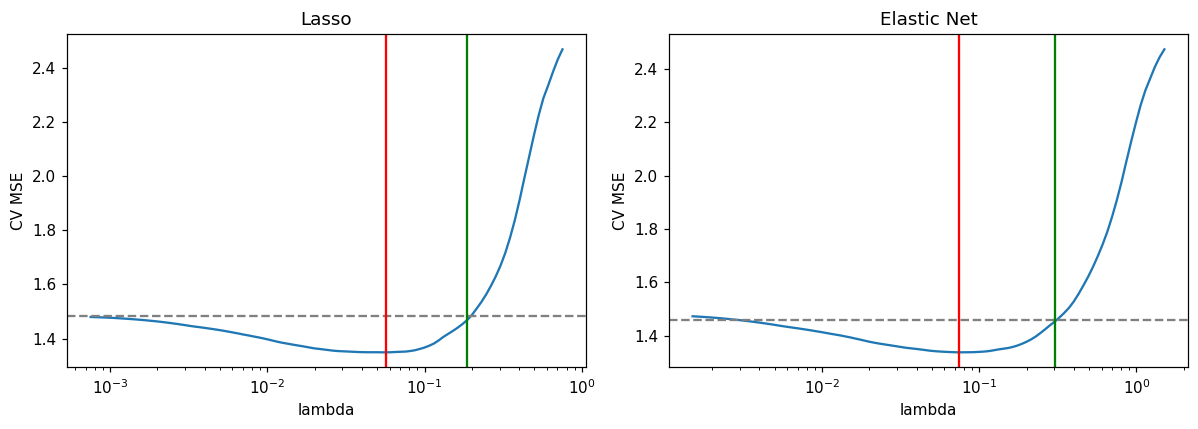

In [5]:
def penalty_grid(A, b, ratio):
    top = np.max(np.abs((A-A.mean(0)).T @ (b-b.mean()))) / (len(b)*ratio)
    return np.geomspace(top, top*1e-3, 100)

def en_path(A, b, ratio, grid):
    am, bm = A.mean(0), b.mean()
    _, B, gap = enet_path(np.asfortranarray(A-am), b-bm, l1_ratio=ratio,
                         alphas=grid, tol=1e-10, max_iter=200000)
    return B, am, bm

en_results = {}
rows = []
for name, ratio in [('Lasso', 1.0), ('Elastic Net', 0.5)]:
    grid = penalty_grid(X, y, ratio)
    err = []
    for a, v in folds:
        B, am, bm = en_path(X[a], y[a], ratio, grid)
        err.append(np.mean((y[v, None]-((X[v]-am)@B+bm))**2, axis=0))
    err = np.array(err)
    cv, se = err.mean(0), err.std(0, ddof=1)/np.sqrt(10)
    mi = int(cv.argmin())
    one = int(np.flatnonzero(cv <= cv[mi]+se[mi])[0])
    B, am, bm = en_path(X, y, ratio, grid)
    en_results[name] = dict(grid=grid, cv=cv, se=se, mi=mi, one=one, B=B)
    for label, j in [('min', mi), ('1se', one)]:
        b, b0 = B[:, j], bm-am@B[:, j]
        chk = ElasticNet(alpha=grid[j], l1_ratio=ratio, tol=1e-10, max_iter=200000).fit(X,y)
        assert np.allclose(chk.coef_, b, atol=1e-6)
        active = np.abs(b)>1e-10
        mse = np.mean((yt-(Xt@b+b0))**2)
        rows.append(dict(model=name, rule=label, lam=grid[j], CV=cv[j], nonzero=active.sum(),
                         scores=sum(active[cols.index(s)] for s in scores), test_MSE=mse))
        print(name, label, '| nonzero coefficients:')
        print(pd.Series(b, index=cols).loc[lambda s:s.abs()>1e-10].round(4).to_string())
summary_en = pd.DataFrame(rows)
print(summary_en.round(5).to_string(index=False))
block_table = pd.DataFrame({name: r['B'][:, r['mi']] for name,r in en_results.items()}, index=cols)
print('income and card coefficients at min:')
print(block_table.loc[income4+card4].round(4).to_string())
fig, ax = plt.subplots(1,2,figsize=(11,4))
for axis, (name,r) in zip(ax,en_results.items()):
    axis.semilogx(r['grid'],r['cv']); axis.axhline(r['cv'][r['mi']]+r['se'][r['mi']],ls='--',c='gray')
    axis.axvline(r['grid'][r['mi']],c='r');axis.axvline(r['grid'][r['one']],c='g');axis.set_title(name);axis.set_xlabel('lambda');axis.set_ylabel('CV MSE')
plt.tight_layout();show()

<div dir="rtl" style="text-align: right;">

توی lambda_min، Lasso با لامبدای 0.057 تعداد 17 متغیر و 6 امتیاز را نگه می دارد و خطای آزمون 1.2648 است. Elastic Net با لامبدای 0.075 تعداد 22 متغیر و 8 امتیاز نگه می دارد و خطای آزمون 1.2610 است. اختلاف این سه روش منظم سازی خیلی کوچک است و از این عددها نمی شود برنده قطعی انتخاب کرد.

Lasso از درآمدها total_inflow_mrial و avg_monthly_credit_mrial را نگه می دارد و از هزینه ها card_spend_total_mrial و card_spend_pos_mrial. Elastic Net علاوه بر این ها salary_inflow_rial را هم نگه می دارد. declared_income_mrial و card_spend_online_mrial و n_card_tx توی هر دو مدل صفرند. Elastic Net اعضای بیشتری از گروه هم خط را نگه می دارد، چون جریمه L2 هم دارد.

## ترتیب ورود شش متغیر

توی شبکه صد نقطه ای ممکن است دو متغیر توی یک خانه وارد شوند. برای همین شبکه اصلی را گزارش می کنم و با مسیر دقیق LARS ترتیب داخل خانه های مشترک را چک می کنم. اینجا فقط برای ترتیب از LARS کمک می گیرم، نه انتخاب لامبدا.

</div>

first grid entries:
            variable  grid index   lambda
  salary_inflow_rial           1 0.702219
  total_inflow_mrial           3 0.610755
       savings_ratio           5 0.531203
                 age           6 0.495402
card_spend_pos_mrial           6 0.495402
               Rural          15 0.264381
  credit_utilization          17 0.229945
       branch_visits          21 0.173945
exact first six (lambda at entry boundary):
            variable  knot  lambda entry
  salary_inflow_rial     1      0.752967
  total_inflow_mrial     2      0.626403
       savings_ratio     3      0.564754
card_spend_pos_mrial     4      0.529196
                 age     5      0.508365
               Rural     6      0.266297


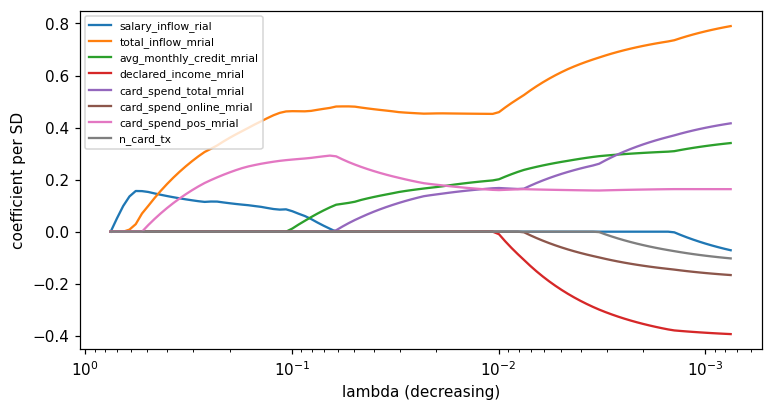

In [6]:
r = en_results['Lasso']
entry_grid = []
for j,c in enumerate(cols):
    hits = np.flatnonzero(np.abs(r['B'][j])>1e-10)
    if len(hits):
        k = hits[0]
        entry_grid.append((c, int(k), r['grid'][k]))
print('first grid entries:')
print(pd.DataFrame(sorted(entry_grid,key=lambda z:z[1])[:8],columns=['variable','grid index','lambda']).to_string(index=False))
al, active, B = lars_path(X-X.mean(0), y-y.mean(), method='lasso')
exact = []
for j,c in enumerate(cols):
    hits = np.flatnonzero(np.abs(B[j])>1e-12)
    if len(hits):
        k=int(hits[0]); exact.append((c,k,al[max(0,k-1)]))
exact.sort(key=lambda z:z[1])
print('exact first six (lambda at entry boundary):')
print(pd.DataFrame(exact[:6],columns=['variable','knot','lambda entry']).to_string(index=False))
plt.figure(figsize=(8,4))
for c in income4+card4:
    j=cols.index(c);plt.semilogx(r['grid'],r['B'][j],label=c)
plt.gca().invert_xaxis();plt.xlabel('lambda (decreasing)');plt.ylabel('coefficient per SD');plt.legend(fontsize=7);show()

<div dir="rtl" style="text-align: right;">

ترتیب دقیق ورود salary_inflow_rial و total_inflow_mrial و savings_ratio و card_spend_pos_mrial و age و Rural است. توی شبکه صد نقطه ای age و card_spend_pos_mrial همزمان دیده می شوند ولی توی مسیر دقیق هزینه پوز زودتر وارد می شود. حقوق اول وارد می شود ولی توی lambda_min صفر شده، یعنی ورود زودهنگام تضمین نمی کند متغیر تا آخر بماند.

## پایداری با بوت استرپ

صد نمونه با جایگذاری از train می گیرم. هر نمونه از نو استاندارد می شود و LassoCV با پنج فولد و seed مشخص برازش می شود. شمارش اصلی با lambda_min است چون سوال مشخص نکرده کدام لامبدا را می خواهد. lambda_1se را هم کنارش می نویسم. صفر بودن را با آستانه خیلی کوچک می سنجم.

توی بوت استرپ نسخه های تکراری یک مشتری ممکن است توی فولدهای مختلف قرار بگیرند. این همان CV معمول روی نمونه بوت استرپ است که سوال خواسته، ولی ارزیابی مستقلی از عملکرد بیرون نمونه نیست و ممکن است انتخاب جریمه را خوش بین کند. درصد انتخاب هم احتمال درست بودن یک متغیر نیست.

</div>

                          min percent  1se percent
salary_inflow_rial               42.0         50.0
total_inflow_mrial               79.0         78.0
avg_monthly_credit_mrial         48.0         33.0
declared_income_mrial            21.0         11.0
card_spend_total_mrial           48.0         34.0
card_spend_online_mrial          26.0         15.0
card_spend_pos_mrial             74.0         76.0
n_card_tx                        33.0         18.0
at least one from group: 1.0
at least one from group: 1.0
mean model size min / 1se: 19.89 12.75


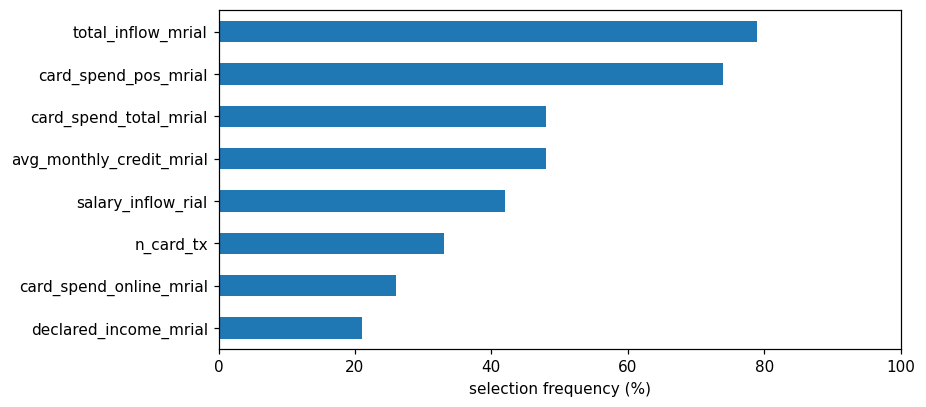

In [7]:
rng = np.random.default_rng(SEED)
Smin, Sone = [], []
bootstrap_lam = []
Araw = train[cols].to_numpy()
for b in range(100):
    idx = rng.integers(0,n,n)
    A, target = Araw[idx], y[idx]
    scale = A.std(0,ddof=1)
    scale = np.where(scale>0,scale,1)
    A = (A-A.mean(0))/scale
    cv5 = KFold(5,shuffle=True,random_state=SEED+b)
    model = LassoCV(cv=cv5,n_alphas=100,eps=1e-3,max_iter=20000,tol=1e-6).fit(A,target)
    means = model.mse_path_.mean(1)
    ses = model.mse_path_.std(1,ddof=1)/np.sqrt(5)
    k = int(means.argmin())
    k1 = int(np.flatnonzero(means<=means[k]+ses[k])[0])
    one = Lasso(alpha=model.alphas_[k1],max_iter=20000,tol=1e-6).fit(A,target)
    Smin.append(np.abs(model.coef_)>1e-10)
    Sone.append(np.abs(one.coef_)>1e-10)
    bootstrap_lam.append(model.alpha_)
Smin, Sone = np.array(Smin), np.array(Sone)
freq = pd.DataFrame({'min percent':100*Smin.mean(0),'1se percent':100*Sone.mean(0)},index=cols)
print(freq.loc[income4+card4].round(0).to_string())
for group in [income4,card4]:
    ids=[cols.index(c) for c in group]
    print('at least one from group:', (Smin[:,ids].sum(1)>0).mean())
print('mean model size min / 1se:', Smin.sum(1).mean(), Sone.sum(1).mean())
plt.figure(figsize=(8,4));freq.loc[income4+card4,'min percent'].sort_values().plot.barh()
plt.xlabel('selection frequency (%)');plt.xlim(0,100);show()

<div dir="rtl" style="text-align: right;">

درصد انتخاب توی lambda_min برای چهار درآمد به ترتیب 42 و 79 و 48 و 21 است و برای هزینه کل و آنلاین و پوز و تعداد تراکنش 48 و 26 و 74 و 33. توی هر صد نمونه حداقل یک درآمد و یک هزینه وارد شد، ولی عضو گروه عوض شد. پس خود گروه پایدار است و انتخاب نماینده اش نه. این هم نتیجه همخطی است، نه اینکه درآمد اظهارشده حتما بی اهمیت باشد. انتخاب کاملا تصادفی هم نیست، چون بعضی اعضا خیلی بیشتر از بقیه انتخاب شدند.

Lasso توی lambda_1se برابر 0.1865 هفت متغیر نگه می دارد و هیچ score ندارد، ولی خطای آزمون 1.4266 است و از OLS کامل هم بالاتر می رود. قاعده یک خطای معیار مدل کوچک تر می دهد ولی تضمین نمی کند روی هر test بهتر باشد.

### 6. سوال 1-د (مفهومی)

## ستون های یکسان

برای لامبدای مثبت هسین تابع هدف Ridge مثبت معین است، چون به ماتریس گرَم یک ماتریس همانی با ضریب مثبت اضافه می شود. پس جواب یکتاست. جابه جا کردن ضریب دو ستون یکسان نه برازش را عوض می کند نه جریمه را، پس از یکتایی دو ضریب باید برابر باشند. هر کدام نصف مجموع شان می شود.

توی Lasso ستون های یکسان فقط از راه مجموع ضرایب شان وارد برازش می شوند. اگر مجموع را s بگذاریم، مجموع قدر مطلق دو ضریب حداقل قدر مطلق s است. برابری وقتی است که دو ضریب هم علامت باشند، یا یکی صفر باشد. با فرض رتبه کامل مدل کاهش یافته، مجموع و بقیه ضرایب یکتا می شوند، ولی شکستن مجموع بین این دو ستون یکتا نیست. همه جواب های بهینه این طورند: اگر s مثبت باشد ضریب اول هر عددی بین صفر و s است و ضریب دوم باقیمانده آن؛ اگر s منفی باشد بازه بین s و صفر است. برای s صفر هر دو صفرند. این توصیف برای لامبدای مثبت است.

## ستون های همبسته و کران Ridge

از شرط مشتق صفر Ridge برای دو ستون کم می کنم. لامبدا ضرب در اختلاف ضرایب برابر ضرب تفاضل دو ستون در باقی مانده می شود. با کوشی شوارتز قدر مطلقش حداکثر نُرم تفاضل ستون ها ضرب نُرم باقی مانده است. چون ستون ها با انحراف معیار نمونه ای استاندارد شده اند، مربع نُرم تفاضل شان برابر دو ضرب در n منهای یک ضرب در یک منهای همبستگی است. جواب Ridge از جواب صفر بدتر نیست، پس نُرم باقی مانده حداکثر نُرم پاسخ مرکزی شده است. با تقسیم بر لامبدا همان کران سوال درمی آید.

## نکته کران Elastic Net

توی Elastic Net اگر دو ضریب هم علامت و غیرصفر باشند، مشتق جریمه L1 توی تفاضل دو شرط حذف می شود. ولی به خاطر مقیاس تابع هدف سوال، مخرج کران n ضرب در لامبدا ضرب در یک منهای آلفاست، نه فقط لامبدا. صورت همان نُرم تفاضل ستون ها ضرب نُرم پاسخ مرکزی شده است. بنابراین کران چاپ شده را برای هر آلفای کمتر از یک بی قید ثابت نمی کنم. اگر n ضرب در یک منهای آلفا حداقل یک باشد، کران چاپ شده از کران درست ضعیف تر است و نتیجه می شود. برای آلفای 0.5 و n برابر 150 این شرط برقرار است. وقتی آلفا به یک برسد بخش L2 حذف می شود و دیگر این استدلال اختلاف ضرایب را کنترل نمی کند.

مرکزی بودن پاسخ اینجا یعنی کم کردن میانگین train. عرض از مبدا جدا و بدون جریمه است. برای کران های ریاضی به همین پاسخ مرکزی شده اشاره می کنم.

</div>

<div dir="rtl" style="text-align: right;">

### 7. سوال 2-الف: مدل های تودرتو

شش مدل صورت سوال را با OLS روی همان train می زنم. استانداردسازی فقط پارامتری سازی را عوض می کند و برای مدل با عرض از مبدا RSS عوض نمی شود. هیچ متغیری از روی test انتخاب نمی شود.

F جزئی را با توزیع دقیق F تحت فرض های مدل خطی گاوسی می سنجم و LRT را با تقریب کای دو. تعداد پارامتر شامل عرض از مبداست و واریانس خطا شمرده نمی شود، همان قرارداد سوال.

</div>

In [8]:
models = [[], basic, basic+['total_inflow_mrial'],
          basic+['total_inflow_mrial','card_spend_total_mrial'],
          basic+['total_inflow_mrial','card_spend_total_mrial']+extra, cols]
cache = {}
def fit_subset(names):
    key=tuple(sorted(names))
    if key not in cache:
        ids=[cols.index(c) for c in key]
        A=np.column_stack([np.ones(n),X[:,ids]])
        At=np.column_stack([np.ones(len(yt)),Xt[:,ids]])
        b=np.linalg.lstsq(A,y,rcond=None)[0]
        rss=float(np.sum((y-A@b)**2))
        param=len(key)+1
        assert np.linalg.matrix_rank(A)==param
        cache[key]=dict(RSS=rss,p=param,AIC=n*np.log(rss/n)+2*param,
                        BIC=n*np.log(rss/n)+param*np.log(n),test_MSE=np.mean((yt-At@b)**2))
    return cache[key]

sigma2=fit_subset(cols)['RSS']/(n-31)
tss=np.sum((y-y.mean())**2)
rows, comparisons=[],[]
for i,names in enumerate(models):
    r=fit_subset(names)
    rows.append(dict(model=f'M{i}',k=r['p']-1,RSS=r['RSS'],R2=1-r['RSS']/tss,
                     adj_R2=1-(r['RSS']/(n-r['p']))/(tss/(n-1)),AIC=r['AIC'],BIC=r['BIC'],
                     Cp=r['RSS']/sigma2-n+2*r['p'],test_MSE=r['test_MSE']))
    if i:
        prev=fit_subset(models[i-1]); q=r['p']-prev['p']
        F=((prev['RSS']-r['RSS'])/q)/(r['RSS']/(n-r['p']))
        LR=n*np.log(prev['RSS']/r['RSS'])
        comparisons.append(dict(pair=f'M{i-1} -> M{i}',q=q,F=F,p_F=stats.f.sf(F,q,n-r['p']),
                                LR=LR,p_LR=stats.chi2.sf(LR,q)))
model_table=pd.DataFrame(rows)
test_table=pd.DataFrame(comparisons)
print(test_table.to_string(index=False))
# چک مستقل با statsmodels برای F جزئی
for i in range(1,len(models)):
    ids0=[cols.index(c) for c in models[i-1]]; ids1=[cols.index(c) for c in models[i]]
    small=sm.OLS(y,np.column_stack([np.ones(n),X[:,ids0]])).fit()
    large=sm.OLS(y,np.column_stack([np.ones(n),X[:,ids1]])).fit()
    fval,pval,qval=large.compare_f_test(small)
    assert np.allclose([fval,pval],[comparisons[i-1]['F'],comparisons[i-1]['p_F']])

    pair  q         F          p_F        LR         p_LR
M0 -> M1  5  5.322088 1.614946e-04 25.435431 1.147886e-04
M1 -> M2  1 54.625814 1.119233e-11 48.529618 3.253381e-12
M2 -> M3  1  5.819774 1.712327e-02  6.025010 1.410456e-02
M3 -> M4  7  8.340795 1.905144e-08 53.911676 2.448422e-09
M4 -> M5 16  0.968300 4.954275e-01 18.358072 3.033499e-01


<div dir="rtl" style="text-align: right;">

تا M4 همه اضافه شدن ها معنادارند. درآمد توی M2 خیلی معنادار است، هزینه کل توی M3 با p برابر 0.017 و هفت متغیر بعدی توی M4 با p حدود 2e-8. اما M4 به M5 معنادار نیست، F برابر 0.968 و p برابر 0.495 است. LRT هم p برابر 0.303 می دهد. پس اضافه کردن آن 16 متغیر توجیه ندارد.

بیشترین اختلاف محسوس p ها توی همین مرحله آخر است، 0.495 و 0.303. نتیجه تصمیم توی سطح پنج درصد عوض نمی شود، ولی LRT شواهد بیشتری برای مدل بزرگ نشان می دهد. F توزیع دقیق نمونه محدود دارد و تقریب کای دوی LRT مجانبی است. اینجا فقط 150 مشاهده و توی مدل کامل 31 پارامتر داریم، پس اختلاف تقریب ها مهم می شود.

### 8. سوال 2-ب: معیارهای مقایسه

RSS و R2 جریمه ای برای بزرگی مدل ندارند. R2 تعدیل شده و AIC و BIC و Cp را هم کنارش می گذارم. واریانس توی Cp از مدل M5 است و بر درجه آزادی باقی مانده تقسیم شده، نه n.

</div>

model  k       RSS      R2  adj_R2       AIC       BIC        Cp  test_MSE
   M0  0 367.30579 0.00000 0.00000 136.33391 139.34455 180.38571   2.89757
   M1  5 310.01639 0.15597 0.12667 120.89848 138.96229 139.16676   2.84255
   M2  6 224.32466 0.38927 0.36364  74.36886  95.44331  64.55500   1.75559
   M3  7 215.49284 0.41331 0.38439  70.34386  94.42894  58.65901   1.58045
   M4 14 150.43280 0.59044 0.54797  30.43218  75.59171  14.49280   1.19530
   M5 30 133.10381 0.63762 0.54627  44.07411 137.40380  31.00000   1.38169
sigma2 M5: 1.1185194023886424
RSS minimum: M5
AIC minimum: M4
BIC minimum: M4
Cp minimum: M4
test_MSE minimum: M4
R2 maximum: M5
adj_R2 maximum: M4


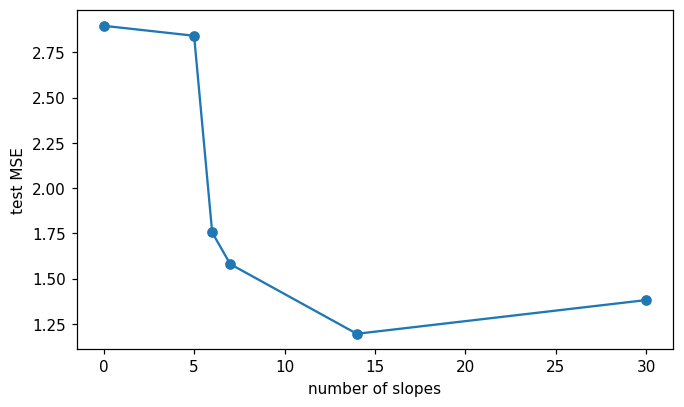

In [9]:
print(model_table.round(5).to_string(index=False))
print('sigma2 M5:',sigma2)
for c in ['RSS','AIC','BIC','Cp','test_MSE']:
    print(c,'minimum:',model_table.loc[model_table[c].idxmin(),'model'])
for c in ['R2','adj_R2']:
    print(c,'maximum:',model_table.loc[model_table[c].idxmax(),'model'])
assert np.isclose(model_table.loc[5,'Cp'],31)
plt.figure(figsize=(7,4))
plt.plot(model_table['k'],model_table['test_MSE'],'o-')
plt.xlabel('number of slopes');plt.ylabel('test MSE');show()

<div dir="rtl" style="text-align: right;">

RSS و R2 مدل کامل M5 را می خواهند، چون با اضافه کردن ستون RSS نمی تواند بیشتر شود. R2 تعدیل شده M4 را انتخاب می کند، 0.5480 در برابر 0.5463 برای M5. AIC و BIC و Cp هم هر سه کمترین مقدار را توی M4 دارند، یعنی 30.43 و 75.59 و 14.49. خطای آزمون M4 هم 1.1953 است در برابر 1.3817 مدل کامل، ولی این خطا را برای انتخاب استفاده نکردم.

Cp مدل کامل دقیقا 31 می شود. دلیلش تعریف است: RSS مدل کامل تقسیم بر واریانس همان مدل برابر درجه آزادی باقی مانده است، یعنی 119. بعد منهای 150 و به اضافه دو برابر 31 می شود 31. این برابری خودش نشانه درست بودن یا خوب بودن مدل کامل نیست.

### 9. سوال 2-ج: انتخاب گام به گام

همه 30 ستون کاندیدند و عرض از مبدا همیشه هست. Town و Rural را جداگانه انتخاب می کنم، چون سوال روی 30 پیش بین است، نه انتخاب گروهی عامل شعبه. هر بار بهترین اضافه یا حذف را از نظر معیار انجام می دهم و وقتی هیچ حرکت بهتری نیست می ایستم. دوطرفه از مدل تهی شروع می شود و هر دو حرکت اضافه و حذف را بررسی می کند. معیار و مجموعه نهایی ممکن است به مسیر وابسته باشند و این جستجو تضمین بهترین زیرمجموعه بین همه مدل ها نیست.

</div>

In [10]:
def stepwise(direction, criterion):
    selected=set(cols) if direction=='backward' else set()
    history=[]
    while True:
        current=fit_subset(selected)[criterion]
        moves=[]
        if direction!='backward':
            for c in cols:
                if c not in selected:
                    moves.append((fit_subset(selected|{c})[criterion],'add',c))
        if direction!='forward':
            for c in cols:
                if c in selected:
                    moves.append((fit_subset(selected-{c})[criterion],'drop',c))
        if not moves:
            break
        value,action,c=min(moves,key=lambda t:(t[0],t[1],t[2]))
        if value>=current-1e-9:
            break
        if action=='add': selected.add(c)
        else: selected.remove(c)
        history.append((action,c,value))
    return [c for c in cols if c in selected],history

step_rows=[]
for direction,criterion in [('forward','AIC'),('backward','AIC'),('both','AIC'),('forward','BIC'),('backward','BIC')]:
    selected,history=stepwise(direction,criterion)
    r=fit_subset(selected)
    step_rows.append(dict(method=direction+' '+criterion,k=len(selected),
                          n_score=len(set(selected)&set(scores)),test_MSE=r['test_MSE'],
                          AIC=r['AIC'],BIC=r['BIC'],selected=', '.join(selected),
                          income=', '.join(c for c in income4 if c in selected),
                          card=', '.join(c for c in card4 if c in selected)))
    print(direction,criterion,'| selected:',selected)
    print('path:',[(act,c,round(value,3)) for act,c,value in history])
step_table=pd.DataFrame(step_rows)
print(step_table.drop(columns='selected').round(5).to_string(index=False))

forward AIC | selected: ['age', 'Rural', 'salary_inflow_rial', 'card_spend_pos_mrial', 'savings_ratio', 'credit_utilization', 'branch_visits', 'score_02', 'score_05', 'score_09']
path: [('add', 'salary_inflow_rial', 98.526), ('add', 'savings_ratio', 70.66), ('add', 'age', 49.1), ('add', 'card_spend_pos_mrial', 37.338), ('add', 'credit_utilization', 32.624), ('add', 'Rural', 26.641), ('add', 'branch_visits', 23.032), ('add', 'score_05', 19.858), ('add', 'score_02', 18.611), ('add', 'score_09', 17.81)]
backward AIC | selected: ['age', 'Rural', 'total_inflow_mrial', 'card_spend_total_mrial', 'savings_ratio', 'credit_utilization', 'branch_visits', 'score_02', 'score_05']
path: [('drop', 'atm_withdrawals', 42.087), ('drop', 'salary_inflow_rial', 40.154), ('drop', 'score_03', 38.263), ('drop', 'tenure_years', 36.384), ('drop', 'credit_limit_mrial', 34.498), ('drop', 'n_card_tx', 32.646), ('drop', 'score_08', 30.779), ('drop', 'card_spend_pos_mrial', 28.905), ('drop', 'score_07', 27.254), ('d

<div dir="rtl" style="text-align: right;">

پیشرو و دوطرفه AIC هر دو 10 متغیر با سه score نگه می دارند و خطای آزمون 1.3460 است. پسرو AIC نه متغیر با دو score و خطای 1.3271 دارد. پیشرو و پسرو BIC هر دو هشت متغیر با یک score نگه می دارند و خطاهایشان 1.2990 و 1.3009 است.

در همه روش ها age و Rural و savings_ratio و credit_utilization و branch_visits و score_05 مشترک اند. پیشرو نماینده درآمد را salary_inflow_rial و هزینه را card_spend_pos_mrial می گیرد. پسرو total_inflow_mrial و card_spend_total_mrial را نگه می دارد. از score ها پیشرو AIC سه تا 02 و 05 و 09 را دارد، پسرو AIC دو تا 02 و 05 و BIC فقط 05. دوطرفه توی این داده هیچ حرکت حذفی انجام نداد و همان پیشرو شد.

پیشرو از مدل خالی شروع می کند و اول حقوق وارد می شود چون به تنهایی کاهش خوبی می دهد. بعد متغیرهای هم خط دیگر چیز زیادی اضافه نمی کنند. پسرو از مدل کامل شروع می کند و سهم حقوق را در حضور بقیه می سنجد، که کم است و حذفش می کند. به همین دلیل دو مسیر نماینده متفاوت می گیرند و هیچ کدام ثابت نمی کنند آن متغیر ذاتا مهم تر است.

## مقایسه با سوال 1

MSE آزمون M4 برابر 1.1953 و سه روش منظم سازی توی lambda_min حدود 1.261 تا 1.265 است. روش های گام به گام حدود 1.299 تا 1.346 و OLS کامل 1.3817 است. روی همین test مدل M4 کمترین خطا را دارد. بین گام به گام ها BIC کوچکتر و بهتر از AIC است، ولی از این ترتیب نمی شود برتری آماری قطعی نتیجه گرفت. انتخاب نهایی را با معیار train گزارش می کنم و test را صرفا ارزیابی می گیرم.

### 10. سوال 2-د (مفهومی)

## شرط انتخاب AIC و BIC

مدل بزرگ تر را یک و کوچک تر را صفر نام گذاری می کنم و تعداد پارامترها شامل عرض از مبداست. تفاوت AIC برابر n ضرب در لگاریتم نسبت RSS بزرگ به کوچک به اضافه دو برابر q است. منفی بودن این تفاوت یعنی LRT از دو برابر q بیشتر است.

از تعریف F جزئی، نسبت RSS کوچک به بزرگ برابر یک به اضافه q ضرب در F تقسیم بر n منهای p1 است. این را توی شرط AIC می گذارم و از دو طرف نمایی می گیرم. نتیجه این است که F باید از نسبت n منهای p1 به q ضرب در نمای دو q بر n منهای یک بیشتر باشد. این همان شرط سوال است.

برای BIC به جای دو q، q ضرب در لگاریتم n می آید. پس کران متناظر می شود نسبت n منهای p1 به q ضرب در n به توان q بر n منهای یک.

## حد مجانبی

تحت فرض صفر و با شرایط معمول مدل گاوسی، LRT به کای دو با q درجه آزادی میل می کند. آستانه AIC دو برابر q است و ثابت می ماند، پس احتمال اضافه کردن متغیر بی اثر به صفر نمی رسد. عددها را پایین از تابع بقا حساب می کنم.

BIC آستانه q ضرب در لگاریتم n دارد و این به بی نهایت می رود، پس احتمال انتخاب مدل بیش از اندازه به صفر می رسد. اگر مدل کوچک غلط باشد و اثر حذف شده ثابت و غیرصفر باشد، LRT از مرتبه n رشد می کند و از لگاریتم n جلو می زند، پس مدل کوچک غلط هم کنار می رود. با فرض وجود مدل درست در یک مجموعه ثابت از مدل های کاندید و شرایط شناسایی، BIC سازگار است. AIC چون احتمال بیش برازشش مثبت می ماند سازگار نیست. این گزاره برای هر مجموعه در حال رشد یا هر مدل غلط بی قید درست نیست.

## شرط Cp

تفاوت Cp مدل بزرگ و کوچک برابر منفی کاهش RSS تقسیم بر واریانس برآوردی M5 به اضافه دو q است. برای اینکه منفی شود کاهش RSS تقسیم بر q و سپس تقسیم بر واریانس M5 باید از دو بیشتر باشد. این یک F مانند با مخرج مشترک M5 است، نه لزوما F معمول با مخرج واریانس مدل بزرگ. همین شرط خواسته شده است.

</div>

In [11]:
q_values=np.array([1,2,3,5,10,20])
print(pd.DataFrame({'q':q_values,'alpha_AIC':stats.chi2.sf(2*q_values,q_values)}).to_string(index=False))
# چک جبری شرط ها روی پنج جفت همین داده
for i in range(1,len(models)):
    r0,r1=fit_subset(models[i-1]),fit_subset(models[i])
    q=r1['p']-r0['p']
    F=((r0['RSS']-r1['RSS'])/q)/(r1['RSS']/(n-r1['p']))
    cut_A=(n-r1['p'])/q*np.expm1(2*q/n)
    cut_B=(n-r1['p'])/q*np.expm1(q*np.log(n)/n)
    common_F=(r0['RSS']-r1['RSS'])/(q*sigma2)
    cp0=r0['RSS']/sigma2-n+2*r0['p']
    cp1=r1['RSS']/sigma2-n+2*r1['p']
    assert (r1['AIC']<r0['AIC']) == (F>cut_A)
    assert (r1['BIC']<r0['BIC']) == (F>cut_B)
    assert (cp1<cp0) == (common_F>2)
    print(f'M{i-1}->M{i}: F={F:.4f}, AIC cutoff={cut_A:.4f}, BIC cutoff={cut_B:.4f}, common-variance F={common_F:.4f}')

 q  alpha_AIC
 1   0.157299
 2   0.135335
 3   0.111610
 5   0.075235
10   0.029253
20   0.004995
M0->M1: F=5.3221, AIC cutoff=1.9854, BIC cutoff=5.2352, common-variance F=10.2438
M1->M2: F=54.6258, AIC cutoff=1.9194, BIC cutoff=4.8575, common-variance F=76.6118
M2->M3: F=5.8198, AIC cutoff=1.9060, BIC cutoff=4.8235, common-variance F=7.8960
M3->M4: F=8.3408, AIC cutoff=1.8867, BIC cutoff=5.0804, common-variance F=8.3095
M4->M5: F=0.9683, AIC cutoff=1.7686, BIC cutoff=5.2549, common-variance F=0.9683


<div dir="rtl" style="text-align: right;">

سطح معادل AIC برای q برابر 1 و 2 و 3 و 5 و 10 و 20 حدود 0.1573 و 0.1353 و 0.1116 و 0.0752 و 0.0293 و 0.0050 است. این عددها با زیاد شدن n و ثابت ماندن q به صفر نمی روند. هر سه شرط AIC و BIC و Cp را روی مدل های همین داده چک کردم و با مقایسه مستقیم معیارها یکسان بود.

### 11. جمع بندی و محدودیت ها

مشکل اصلی این داده همخطی گروه درآمد و هزینه است. Ridge اثر گروه را بین اعضا پخش می کند و Lasso نماینده ها را عوض می کند. بوت استرپ هم پایداری گروه و ناپایداری عضو را نشان داد. انتخاب گام به گام هم بسته به مسیر عضو متفاوتی نگه داشت.

قراردادهای محاسبه من روشن اند: همه مقیاس ها از train، انحراف معیار نمونه ای، CV ثابت، df Ridge بدون عرض از مبدا، انتخاب بوت استرپ اصلی با lambda_min و آستانه غیرصفر یک در ده به توان منفی ده. هیچ مشتری را حذف نکردم و برای مسئله همخطی ستون درآمد یا هزینه را هم از قبل کنار نگذاشتم، چون خود سوال مقایسه این رفتارها را می خواست.

مقیاس گذاری قبل از CV روی کل train انجام شده، پس این CV نسبت به مقیاس گذاری داخل فولد کمی اطلاعات از فولد اعتبارسنجی می گیرد. test توی هیچ تنظیمی دخالت نکرده. درصد انتخاب بوت استرپ احتمال واقعی بودن اثر نیست. زیاد شدن MSE از train به test هم به تنهایی اثبات بیش برازش نیست.

کران Elastic Net چاپ شده را جدا از کران حاصل از تابع هدف توضیح دادم. نتیجه بدون اصلاح ضریب مخرج برای هر آلفای کمتر از یک ادعا نشده است.

بخش های مفهومی اینجا توضیح متنی دارند. برای تحویل دستی باید همان استدلال ها روی برگه نوشته و اسکن شوند؛ عکسی که هنوز ندارم را به فایل اضافه نکردم.

منابع روش ها: ISL، فصل 6 برای منظم سازی و انتخاب زیرمجموعه؛ ESL، فصل 3 برای Ridge و Lasso. قرارداد شبکه ها و معیارها از صورت کوییز 3 است.

</div>